#1
Churn reasons:  before 2023:online handling. after 2024 february: after 1 year, 2023 01-, TV, New York based, often sub for gifts
investigate in New York

Database: 
1. SubscriptionID  
2. HH Income 
3. Home Ownership 
4. Ethnicity 
5. dummy for Children 
6. Year Of Residence 
7. Age range 
8. Language 
9. Address 
10. State  
11. City 
12. County  
13. Zip Code 
14. monthly fee 
15. Device 
16. Nielsen Prizm 
17. Reward program (how many times did the subscriber use the reward program) 
18. Source Channel 
19. Subscriber

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
def load_data(file_path):
    try:
        data = pd.read_excel(file_path)
        return data
    except Exception as e:
        print(f"Error loading data: {e}")
        return None

file_path = 'ZenaraChurn.xlsx'

df = load_data(file_path)

df.head()

,SubscriptionID,HH Income,Home Ownership,Ethnicity,dummy for Children,Year Of Residence,Age range,Language,State,City,County,Zip Code,monthly fee,Device,Nielsen Prizm,reward program,Source Channel,Subscriber
0,181401653,"$500,000 Plus",OWNER,unknown,Y,14,50-54,NaN,NY,QUEENS VILLAGE,QUEENS,11379,$0.04-$2.00,Chrome,MW,0,Facebook Ads,YES
1,180374685,"$100,000 - $124,999",OWNER,Italian,Y,7,45-49,English,NY,FRESH MEADOWS,QUEENS,11358,$0.04-$2.00,Chrome,MW,0,Facebook Ads,YES
2,180358906,"$ 50,000 - $59,999",OWNER,Italian,N,23,60-64,English,NY,BELLEROSE,QUEENS,11425,$32.00-$35.96,Edge,MM,0,Google Ads,YES
3,140606609,"$150,000 - $174,999",OWNER,English,N,4,75 years or more,English,NY,BAYSIDE,QUEENS,11422,$8.00-$11.96,Opera,YW,0,Google Ads,NO
4,180571846,"$175,000 - $199,999",OWNER,Chinese,N,2,45-49,English,NY,BAYSIDE,QUEENS,11367,$8.00-$11.96,Chrome,MW,0,Kiosk,NO


1: Investigate the database, county and subscriber connection
Rewardprogram- Subcriber connection

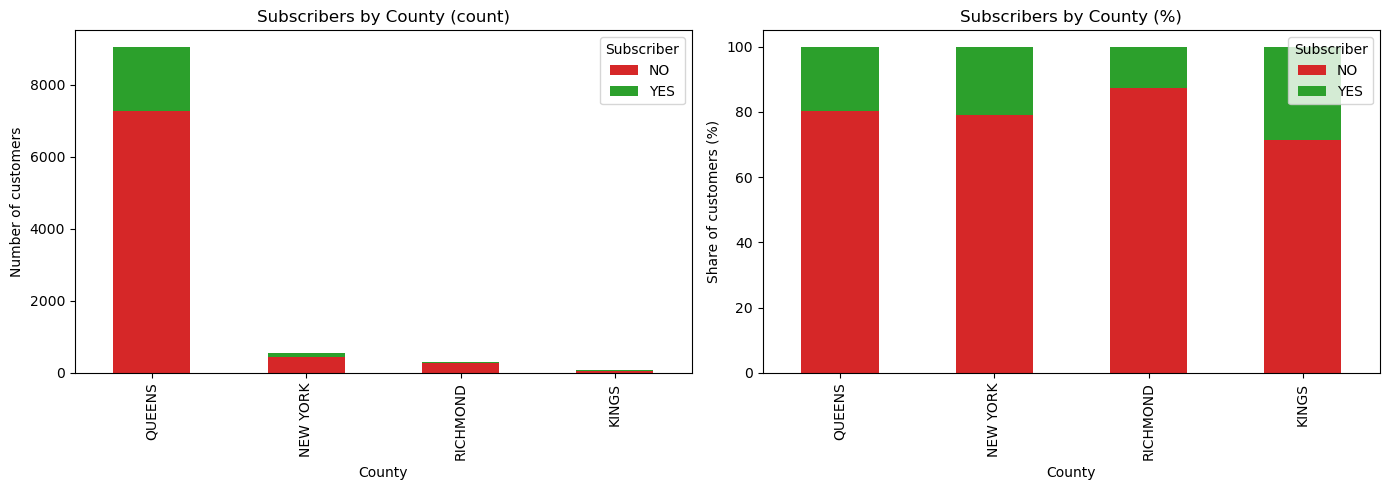

Subscriber,NO,YES
County,,
QUEENS,80.4,19.6
NEW YORK,79.1,20.9
RICHMOND,87.3,12.7
KINGS,71.4,28.6


In [2]:

#county and Subcriber stacked barchart
county_sub = pd.crosstab(df['County'], df['Subscriber'])
county_sub = county_sub.loc[county_sub.sum(axis=1).sort_values(ascending=False).index]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Counts
county_sub.plot(kind='bar', stacked=True, ax=axes[0], color=['#d62728', '#2ca02c'])
axes[0].set_title('Subscribers by County (count)')
axes[0].set_xlabel('County')
axes[0].set_ylabel('Number of customers')
axes[0].legend(title='Subscriber')

# Shares (100% stacked) - makes churn rates comparable across counties
county_share = county_sub.div(county_sub.sum(axis=1), axis=0) * 100
county_share.plot(kind='bar', stacked=True, ax=axes[1], color=['#d62728', '#2ca02c'])
axes[1].set_title('Subscribers by County (%)')
axes[1].set_xlabel('County')
axes[1].set_ylabel('Share of customers (%)')
axes[1].legend(title='Subscriber')

plt.tight_layout()
plt.show()

county_share.round(1)


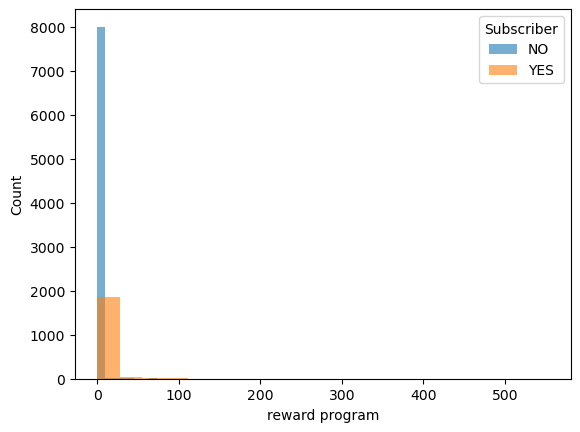

In [3]:
#reward program histogram colored by Subscriber
for value, group in df.groupby('Subscriber'):
    plt.hist(group['reward program'], bins=20, alpha=0.6, label=value)
plt.xlabel('reward program')
plt.ylabel('Count')
plt.legend(title='Subscriber')
plt.show()


In [4]:
#2 Modeling - data preparation
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix

# Target (label) and features
y = df['Subscriber']
X = df.drop(columns=['Subscriber', 'SubscriptionID', 'Zip Code'])

# sklearn only accepts numbers: text columns -> 0/1 dummy columns
X = pd.get_dummies(X).fillna(0)

# Split Data: first 70% train, last 30% test (no shuffling)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, shuffle=False)
X_train.shape, X_test.shape


((7000, 276), (3000, 276))

In [5]:
#Decision tree - Gini (minimal gain 0.01: sklearn scales it differently than RapidMiner, 0.1 gives a single leaf)
tree_gini = DecisionTreeClassifier(criterion='gini', max_depth=10, min_impurity_decrease=0.01)
tree_gini.fit(X_train, y_train)

pred = tree_gini.predict(X_test)
print('Accuracy:', accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))
print(export_text(tree_gini, feature_names=list(X.columns)))


Accuracy: 0.8436666666666667
[[2359   70]
 [ 399  172]]
|--- monthly fee_$40.00-$43.96 <= 0.50
|   |--- reward program <= 0.50
|   |   |--- monthly fee_$0.04-$2.00 <= 0.50
|   |   |   |--- class: NO
|   |   |--- monthly fee_$0.04-$2.00 >  0.50
|   |   |   |--- class: NO
|   |--- reward program >  0.50
|   |   |--- class: YES
|--- monthly fee_$40.00-$43.96 >  0.50
|   |--- class: YES



In [6]:
#Decision tree - Gain ratio (sklearn closest option: entropy = information gain; minimal gain 0.01)
tree_gain = DecisionTreeClassifier(criterion='entropy', max_depth=10, min_impurity_decrease=0.01)
tree_gain.fit(X_train, y_train)

pred = tree_gain.predict(X_test)
print('Accuracy:', accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))
print(export_text(tree_gain, feature_names=list(X.columns)))


Accuracy: 0.8436666666666667
[[2359   70]
 [ 399  172]]
|--- monthly fee_$40.00-$43.96 <= 0.50
|   |--- reward program <= 0.50
|   |   |--- monthly fee_$0.04-$2.00 <= 0.50
|   |   |   |--- Source Channel_Google Ads <= 0.50
|   |   |   |   |--- Year Of Residence <= 16.50
|   |   |   |   |   |--- class: NO
|   |   |   |   |--- Year Of Residence >  16.50
|   |   |   |   |   |--- class: NO
|   |   |   |--- Source Channel_Google Ads >  0.50
|   |   |   |   |--- class: NO
|   |   |--- monthly fee_$0.04-$2.00 >  0.50
|   |   |   |--- class: NO
|   |--- reward program >  0.50
|   |   |--- class: YES
|--- monthly fee_$40.00-$43.96 >  0.50
|   |--- class: YES



In [7]:
#Naive Bayes
nb = GaussianNB()
nb.fit(X_train, y_train)

pred = nb.predict(X_test)
print('Accuracy:', accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))


Accuracy: 0.3396666666666667
[[ 464 1965]
 [  16  555]]


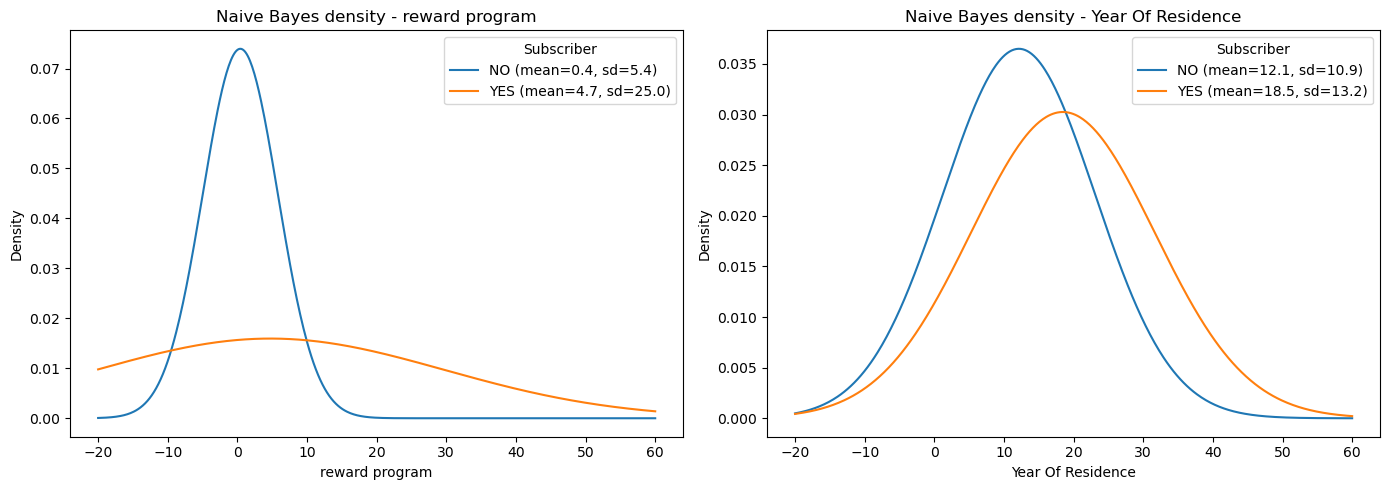

In [8]:
#Naive Bayes density functions: the normal curve the model learned for each class
from scipy.stats import norm

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, x_range in [(axes[0], 'reward program', (-20, 60)), (axes[1], 'Year Of Residence', (-20, 60))]:
    i = list(X.columns).index(col)
    x = np.linspace(*x_range, 500)
    for k, cls in enumerate(nb.classes_):
        mean, sd = nb.theta_[k, i], np.sqrt(nb.var_[k, i])
        ax.plot(x, norm.pdf(x, mean, sd), label=f'{cls} (mean={mean:.1f}, sd={sd:.1f})')
    ax.set_title(f'Naive Bayes density - {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Density')
    ax.legend(title='Subscriber')
plt.tight_layout()
plt.show()


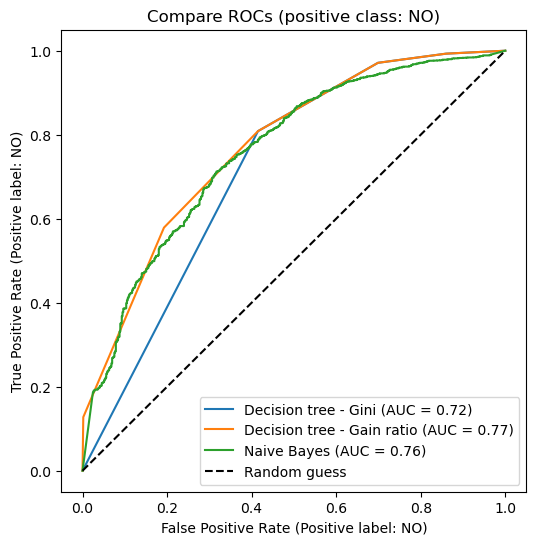

In [9]:
#Compare ROCs - same X_test / y_test as the confusion matrices, positive class = NO (churner)
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 6))
for name, model in [('Decision tree - Gini', tree_gini), ('Decision tree - Gain ratio', tree_gain), ('Naive Bayes', nb)]:
    RocCurveDisplay.from_estimator(model, X_test, y_test, pos_label='NO', name=name, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', label='Random guess')
ax.set_title('Compare ROCs (positive class: NO)')
ax.legend()
plt.show()


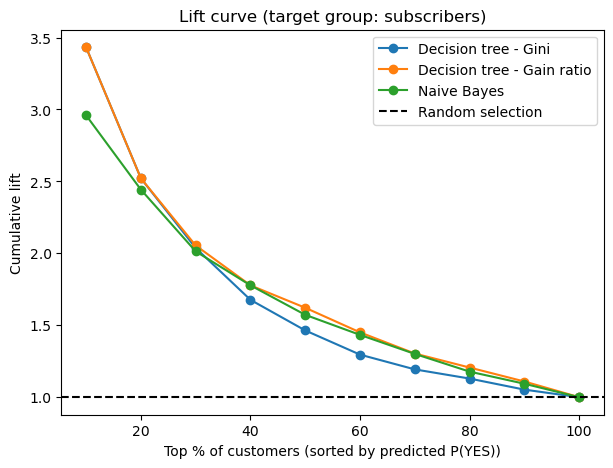

,Decision tree - Gini,Decision tree - Gain ratio,Naive Bayes
top 10%,3.43,3.43,2.96
top 20%,2.52,2.52,2.44
top 30%,2.04,2.05,2.01
top 40%,1.68,1.78,1.78
top 50%,1.46,1.62,1.57
top 60%,1.30,1.45,1.43
top 70%,1.19,1.30,1.30
top 80%,1.13,1.21,1.18
top 90%,1.05,1.11,1.09
top 100%,1.00,1.00,1.00


In [10]:
#Lift curve - target group: subscribers (YES), same test set
is_yes = (y_test == 'YES').values
base_rate = is_yes.mean()              # share of subscribers among all test customers
deciles = np.arange(10, 101, 10)       # top 10%, 20%, ... 100% of customers

lift_table = {}
fig, ax = plt.subplots(figsize=(7, 5))
for name, model in [('Decision tree - Gini', tree_gini), ('Decision tree - Gain ratio', tree_gain), ('Naive Bayes', nb)]:
    # Sort by lowest P(NO) = highest P(YES). Naive Bayes rounds many P(YES) values to exactly 1.0,
    # but the tiny P(NO) values stay distinct, so sorting on P(NO) keeps the correct order.
    p_no = model.predict_proba(X_test)[:, list(model.classes_).index('NO')]
    sorted_yes = is_yes[np.argsort(p_no, kind='stable')]     # most likely subscribers first
    lift = []
    for d in deciles:
        top = sorted_yes[:int(len(sorted_yes) * d / 100)]
        lift.append(top.mean() / base_rate)                   # hit rate in top d% vs. overall rate
    lift_table[name] = lift
    ax.plot(deciles, lift, marker='o', label=name)

ax.axhline(1, color='k', linestyle='--', label='Random selection')
ax.set_xlabel('Top % of customers (sorted by predicted P(YES))')
ax.set_ylabel('Cumulative lift')
ax.set_title('Lift curve (target group: subscribers)')
ax.legend()
plt.show()

pd.DataFrame(lift_table, index=[f'top {d}%' for d in deciles]).round(2)


## Summary

**Setup:** the target is `Subscriber` (NO = churner, about 80% of customers). The first 70% of rows are used for training and the last 30% (3,000 customers) for testing. All three models use the same split. Both trees use max depth 10 and minimal gain 0.01. With 0.1 the trees made no splits at all, because sklearn scales minimal gain differently from RapidMiner.

| Model | Accuracy | Precision for NO (Pno) | ROC AUC |
|---|---|---|---|
| Decision tree – Gini | **84.4%** | 85.5% | 0.72 |
| Decision tree – Gain ratio (entropy) | **84.4%** | 85.5% | **0.77** |
| Naive Bayes | 34.0% | **96.7%** | 0.76 |

**Findings:**
- **The trees reach the best accuracy (84.4%).** Both trees give the same predictions at the default threshold, so their accuracy and Pno are equal. They find 97% of the churners (2,359 of 2,429).
- **Naive Bayes has the highest Pno (96.7%), but it predicts NO only rarely.** It finds just 19% of the churners, which is why its accuracy is low.
- **On the ROC chart, the Gain ratio tree performs best (AUC 0.77),** just ahead of Naive Bayes (0.76). The Gini tree is behind (0.72) because it has fewer leaves and so separates customers less finely.
- **Conclusion:** the **Gain ratio decision tree** predicts churners best overall.

**Churner characteristics (from the trees):** customers whose monthly fee is not $40.00–$43.96 and who never used the reward program are predicted to churn. Paying $40.00–$43.96 per month or using the reward program at least once both point to staying subscribed (YES).


## How to read the decision trees

- **A path from the root to a leaf is one rule.** Read it as "IF condition 1 AND condition 2 AND ... THEN class".
- **Dummy splits:** `monthly fee_$40.00-$43.96 <= 0.5` means the customer is *not* in that fee band, and `> 0.5` means they *are* in it.
- **`reward program <= 0.5`** means the customer never used the reward program (0 times). `> 0.5` means they used it at least once.
- **Each leaf predicts its majority class.** Its churn rate tells you how reliable that prediction is.
- **The higher a split, the more important the variable.** The first split (root) separates the customers best.

## Rules: who will churn (NO)?

Churn rates are measured on the training set (7,000 customers). The test set gives very similar rates.

**Gini tree:**

| # | Rule (IF ...) | Customers | Churn rate | Prediction |
|---|---|---|---|---|
| 1 | fee **not** $40.00–$43.96 AND **never** used reward program AND fee **not** $0.04–$2.00 | 5,176 | 89% | **NO (churns)** |
| 2 | fee **not** $40.00–$43.96 AND **never** used reward program AND fee **is** $0.04–$2.00 | 1,203 | 69% | **NO (churns)** |
| 3 | fee **not** $40.00–$43.96 AND used reward program **at least once** | 382 | 44% | YES (stays) |
| 4 | fee **is** $40.00–$43.96 | 239 | 14% | YES (stays) |

**Gain ratio tree:** rules 2–4 are the same as in the Gini tree. Rule 1 is split further into three smaller groups, all of which churn:

| # | Rule (rule 1 of the Gini tree AND ...) | Customers | Churn rate | Prediction |
|---|---|---|---|---|
| 1a | source channel **is Google Ads** | 805 | **99%** | **NO (churns)** |
| 1b | source channel **not** Google Ads AND lived at address **≤ 16 years** | 2,943 | 91% | **NO (churns)** |
| 1c | source channel **not** Google Ads AND lived at address **> 16 years** | 1,428 | 79% | **NO (churns)** |

**In short:** a customer is likely to churn if they **never used the reward program** and **don't pay $40.00–$43.96 per month**. Churn is almost certain (99%) when such a customer also **came through Google Ads**. Using the reward program even once, or being in the $40.00–$43.96 fee band, are the strongest signs that a customer stays.


In [11]:
#Optional: linear regression - predict the monthly fee from customer characteristics
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Target: fee band -> number (band midpoint), e.g. '$8.00-$11.96' -> 9.98. Rows without a fee are dropped.
reg_df = df.dropna(subset=['monthly fee']).copy()
bounds = reg_df['monthly fee'].str.replace('$', '', regex=False).str.split('-', expand=True).astype(float)
reg_df['fee'] = bounds.mean(axis=1)

# Features: who the customer is and how they arrived (not churn itself, which comes after the fee)
features = ['HH Income', 'Age range', 'Home Ownership', 'dummy for Children',
            'Year Of Residence', 'Device', 'Source Channel', 'County']
# drop_first=True: one category per variable becomes the baseline the coefficients are compared to
# (baselines: Source Channel = AdvAdm, Device = Chrome, ...)
X_reg = pd.get_dummies(reg_df[features], drop_first=True).fillna(0)
y_reg = reg_df['fee']

# Same logic as before: first 70% train, last 30% test
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, train_size=0.7, shuffle=False)

lin = LinearRegression().fit(Xr_train, yr_train)
yr_pred = lin.predict(Xr_test)
print('R2:  ', round(r2_score(yr_test, yr_pred), 3))
print('RMSE:', round(np.sqrt(mean_squared_error(yr_test, yr_pred)), 2), '$')
print('Mean fee in test set:', round(yr_test.mean(), 2), '$')

# Coefficients: $ difference in predicted fee vs. the baseline category.
# Only categories with at least 50 training customers - tiny groups give unreliable coefficients.
coefs = pd.Series(lin.coef_, index=X_reg.columns)
coefs = coefs[Xr_train.sum() >= 50].sort_values()
pd.concat([coefs.head(8), coefs.tail(8)]).round(2)


R2:   0.563
RMSE: 6.92 $
Mean fee in test set: 9.22 $


Device_Motorola                  -1.22
dummy for Children_Y             -0.20
HH Income_Under $20,000          -0.18
Age range_40-44                  -0.09
HH Income_$  40,000 - $49,999     0.02
HH Income_$  30,000 - $39,999     0.04
Year Of Residence                 0.05
Age range_50-54                   0.10
Source Channel_Kiosk             12.20
Source Channel_TikTok Ads        12.23
Source Channel_System            12.31
Source Channel_Direct Advert     12.49
Source Channel_RetenIn           13.06
Source Channel_Crew1             13.97
Source Channel_Youtube Ads       17.83
Source Channel_VRU               21.82
dtype: float64